# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 05
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Three-location cleaning agent | 25 |
| Q2 | Greedy versus A* weighted search | 30 |
| Q3 | Decision-tree depth comparison | 35 |
| Q4 | Viva: agents, heuristics, overfitting, precision/recall/F1 | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_05_A.py) | [Q2 / B](Set_05_B.py) | [Q3 / C](Set_05_C.py) | [Q4 / D: Viva practice](Set_05_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Intelligent Agent (25 marks)
**Question specification**  
Design cleaning agent for A, B, C (Clean/Dirty). Clean current room, otherwise move, and use NoOp when all clean. Print location, percept, action, and environment after each step. Give PEAS.

### Theory and mathematical background
An **agent** senses the environment and selects an **action** from the current percept. A simple reflex rule depends on the current percept only; the rule `Dirty → Suck` is a condition-action rule.

A two-room agent that **stops when every room is clean** needs information beyond a purely local percept (either global sensing or internal state). Therefore the terminating variant is *reflex-style cleaning with global-state access*, not a strictly percept-only reflex agent.

Let $s_t$ denote the current environment and $a_t$ the selected action. A policy chooses $a_t=\pi(s_t)$, and the transition is $s_{t+1}=T(s_t,a_t)$. For the cleaning goal:
$$\text{NoOp when }\bigwedge_{r\in\mathcal{R}}\operatorname{Clean}(r).$$

**PEAS** describes Performance, Environment, Actuators, and Sensors.

In [1]:
# The question does not set initial conditions: these are an explicit reproducible example.
environment={'A':'Dirty','B':'Clean','C':'Dirty'}
locations=['A','B','C']
location='A'
print('Initial state (illustrative):', environment,'| starting at',location)
for step in range(1,14):
    percept=(location,environment[location])
    if all(s=='Clean' for s in environment.values()): action='NoOp'
    elif environment[location]=='Dirty': action='Suck'
    else: action='MoveRight'  # Cyclic route A -> B -> C -> A
    if action=='Suck': environment[location]='Clean'
    elif action=='MoveRight': location=locations[(locations.index(location)+1)%3]
    print(f'{step:02d} | location={percept[0]} | percept={percept} | action={action:9} | after={environment}')
    if action=='NoOp': break
assert all(s=='Clean' for s in environment.values())


Initial state (illustrative): {'A': 'Dirty', 'B': 'Clean', 'C': 'Dirty'} | starting at A
01 | location=A | percept=('A', 'Dirty') | action=Suck      | after={'A': 'Clean', 'B': 'Clean', 'C': 'Dirty'}
02 | location=A | percept=('A', 'Clean') | action=MoveRight | after={'A': 'Clean', 'B': 'Clean', 'C': 'Dirty'}
03 | location=B | percept=('B', 'Clean') | action=MoveRight | after={'A': 'Clean', 'B': 'Clean', 'C': 'Dirty'}
04 | location=C | percept=('C', 'Dirty') | action=Suck      | after={'A': 'Clean', 'B': 'Clean', 'C': 'Clean'}
05 | location=C | percept=('C', 'Clean') | action=NoOp      | after={'A': 'Clean', 'B': 'Clean', 'C': 'Clean'}


### PEAS — three-room cleaning robot
| Component | This task |
|:--|:--|
| Performance | All rooms cleaned, few unnecessary moves, low energy use |
| Environment | Three connected rooms A, B, C; each can be dirty or clean |
| Actuators | Suction motor (`Suck`), locomotion (`MoveRight`), idle (`NoOp`) |
| Sensors | Current location, current room dirt sensor, full clean-state signal or internal memory |

This is a **reflex-style policy with global cleanliness access** to meet the stopping requirement; a strictly local simple-reflex agent cannot generally know that every other room is clean.

---
## Q2. Greedy and A* Search (30 marks)
**Question specification**  
Costs: `A-B=2, A-C=3, B-D=4, B-E=2, C-E=2, D-G=3, E-G=4`; h(A,B,C,D,E,G)=(6,5,4,2,3,0). Show Greedy and A* expanded order, route and cost; explain why h-only can fail.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from itertools import count

import heapq

def astar(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    best_g = {start: 0}
    expanded = []
    while heap:
        f, _, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')): continue  # stale entry
        expanded.append((node, g, h[node], f))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            new_g = g + weight
            if new_g < best_g.get(nxt, float('inf')):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g+h[nxt], next(counter), new_g, nxt, path+[nxt]))
    return None, float('inf'), expanded

def greedy_weighted(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    seen, expanded = set(), []
    while heap:
        _, _, g, node, path = heapq.heappop(heap)
        if node in seen: continue
        seen.add(node)
        expanded.append((node, g, h[node]))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            if nxt not in seen:
                heapq.heappush(heap, (h[nxt], next(counter), g+weight, nxt, path+[nxt]))
    return None, float('inf'), expanded

def display_astar_trace(trace):
    print("Node     g(n)     h(n)     f(n)")
    for node, g, h, f in trace:
        print(f"{node:>4} {g:>8} {h:>8} {f:>8}")

graph={'A':[('B',2),('C',3)],'B':[('D',4),('E',2)],
       'C':[('E',2)],'D':[('G',3)],'E':[('G',4)],'G':[]}
h={'A':6,'B':5,'C':4,'D':2,'E':3,'G':0}
greedy_path,greedy_cost,greedy_trace=greedy_weighted(graph,h,'A','G')
a_path,a_cost,a_trace=astar(graph,h,'A','G')
print('Greedy expanded (node,g,h):',greedy_trace,'| path:',greedy_path,'| cost:',greedy_cost)
print('A* expanded (node,g,h,f):',a_trace,'| path:',a_path,'| cost:',a_cost)
display_astar_trace(a_trace)
assert a_cost <= greedy_cost


Greedy expanded (node,g,h): [('A', 0, 6), ('C', 3, 4), ('E', 5, 3), ('G', 9, 0)] | path: ['A', 'C', 'E', 'G'] | cost: 9
A* expanded (node,g,h,f): [('A', 0, 6, 6), ('B', 2, 5, 7), ('C', 3, 4, 7), ('E', 4, 3, 7), ('D', 6, 2, 8), ('G', 8, 0, 8)] | path: ['A', 'B', 'E', 'G'] | cost: 8
Node     g(n)     h(n)     f(n)
   A        0        6        6
   B        2        5        7
   C        3        4        7
   E        4        3        7
   D        6        2        8
   G        8        0        8


### Result interpretation and discussion
Greedy chooses the next node by $h$ alone. In this graph, a path through B→D is tempting when D has a low heuristic, but the paid edge costs matter; A* weighs both. The $h$ values given in the question are used **unchanged**. A* optimum is verified by the accumulated cost, not the number of visited states.

---
## Q3. Decision Tree Classification (35 marks)
**Question specification**  
Use Iris stratified 70/30 split. Train Decision Trees with `max_depth=1,2,3,4,None`; show train/test accuracy, best model confusion matrix, precision, recall, F1, and discuss fit.

### Theory and mathematical background
A **decision tree** recursively chooses feature thresholds that reduce node impurity. One measure is Gini impurity:
$$Gini(D)=1-\sum_{c=1}^{K}p(c\mid D)^2.$$
Restricting `max_depth` reduces complexity but can cause underfitting; large or unrestricted depth can memorize training samples and overfit.

For each class, $Precision=\frac{TP}{TP+FP}$, $Recall=\frac{TP}{TP+FN}$, and $F_1=\frac{2PR}{P+R}$. Macro averages assign equal weight to every class.

Iris samples: (150, 4) | train: 105 | test: 45
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


max_depth  train_acc  test_acc
        1     0.6667    0.6667
        2     0.9714    0.8889
        3     0.9810    0.9778
        4     0.9905    0.8889
     None     1.0000    0.9333
Best depth (on given holdout): 3
Confusion matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



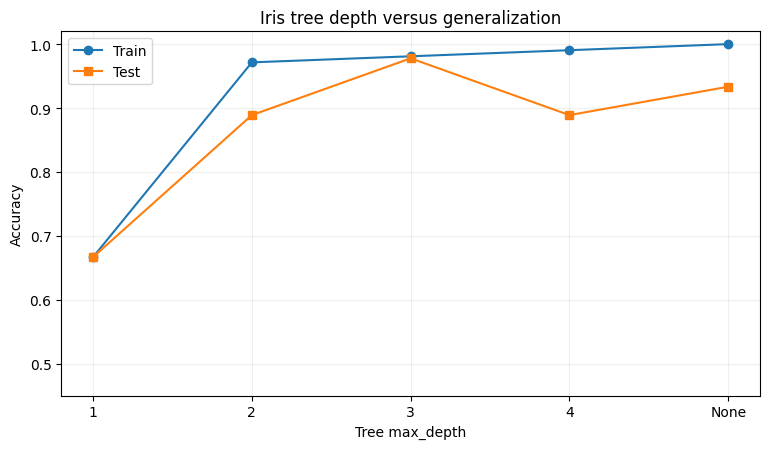

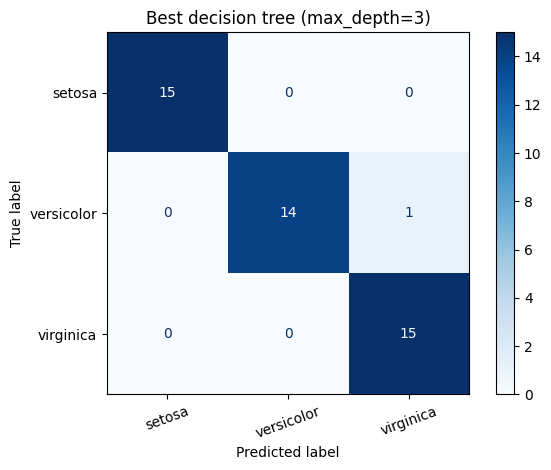

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
import numpy as np
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
                                                    stratify=y, random_state=42)
print('Iris samples:', X.shape, '| train:', len(y_train), '| test:', len(y_test))
print('Class order:', list(iris.target_names))

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
scores, trained={},{ }
for depth in [1,2,3,4,None]:
    model=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X_train,y_train)
    scores[depth]=(model.score(X_train,y_train),model.score(X_test,y_test))
    trained[depth]=model
results=pd.DataFrame([{'max_depth':str(d),'train_acc':scores[d][0],
                       'test_acc':scores[d][1]} for d in [1,2,3,4,None]])
print(results.round(4).to_string(index=False))
# Deterministic ties: prefer the simplest depth, with unlimited last.
best_depth=max([1,2,3,4,None],key=lambda d:(scores[d][1],-({None:999}.get(d,d))))
best=trained[best_depth]
pred=best.predict(X_test)
print('Best depth (on given holdout):',best_depth)
print('Confusion matrix:\n',confusion_matrix(y_test,pred))
print(classification_report(y_test,pred,target_names=iris.target_names,zero_division=0))
depth_names=['1','2','3','4','None']
plt.figure(figsize=(7.8,4.6))
plt.plot(depth_names,results.train_acc,marker='o',label='Train')
plt.plot(depth_names,results.test_acc,marker='s',label='Test')
plt.xlabel('Tree max_depth');plt.ylabel('Accuracy');plt.ylim(0.45,1.02)
plt.title('Iris tree depth versus generalization');plt.grid(alpha=.2);plt.legend();plt.tight_layout();plt.show()
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=iris.target_names,
                                        cmap='Blues',xticks_rotation=20)
plt.title(f'Best decision tree (max_depth={best_depth})');plt.tight_layout();plt.show()


### Result interpretation and discussion
Small depth is less flexible (possible **underfitting**). Large depth may achieve very high training accuracy yet no improvement in test accuracy (**overfitting risk**). For this lab, the question asks to compare on the test set; for a proper unbiased estimate, pick depth through cross-validation on training data, then evaluate the test set once.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| Simple reflex agent? | Uses condition-action rules based on current percept only. |
| What is a state? | Current representation of the environment/problem. |
| Greedy versus A*? | Greedy minimizes h; A* minimizes g+h. |
| What is a tree split? | A feature-and-threshold test dividing samples. |
| Underfitting? | Model too simple to learn relevant patterns. |
| Overfitting? | Model fits training details/noise and generalizes poorly. |
| Precision/Recall/F1? | Precision: TP/(TP+FP); recall: TP/(TP+FN); F1: harmonic mean. |

| Why is Greedy not always optimal? | It considers h(n) only and can ignore the cost already paid, g(n). |
| Why compare training and test accuracy? | A large training-test performance gap can indicate overfitting. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.